# Week 3 — 04: Evaluation and Diagnostics

Calibrate operating points on validation, then evaluate both models independently
on the complete untouched test set.  Also searches fusion rules.


In [1]:
import sys, pathlib

# Resolve project root so notebooks work regardless of CWD or kernel launch dir
_this_nb  = pathlib.Path(__file__) if "__file__" in dir() else pathlib.Path().resolve()
_sentinel = "src"   # directory that marks the project root
_root     = _this_nb.resolve()
for _ in range(10):                          # walk up at most 10 levels
    if (_root / _sentinel).is_dir():
        break
    _root = _root.parent

# Hard-code fallback for direct kernel launch from notebooks/week3/
_fallback = pathlib.Path("/home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project")
if not (_root / _sentinel).is_dir():
    _root = _fallback

if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

PROJECT_ROOT = _root
print("Project root:", PROJECT_ROOT)


Project root: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project


In [2]:
from src import state
import numpy as np, pandas as pd

model_A, model_B = state.load("03_models")
pA_val, pB_val, pB_val_spec, y_complete_val, yA_val, yB_val = state.load("03_val_scores")
(X, feature_cols, train_A_mask, val_A_mask, train_B_mask, val_B_mask,
 X_complete_val, X_complete_test, y_complete_test,
 train_base, val_base, test_base, patterned, unpatterned,
 train_idx, val_idx, test_idx) = state.load("03_matrices")
df = state.load("02_df_features")
print(f"Models loaded. VAL size: {len(y_complete_val):,}")


Loaded checkpoint: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/03_models.pkl
Loaded checkpoint: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/03_val_scores.pkl
Loaded checkpoint: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/03_matrices.pkl
Loaded checkpoint: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/02_df_features.pkl
Models loaded. VAL size: 1,015,701


In [3]:
from src.evaluation import threshold_at_precision_floor, recall_at_floor
from src.config import PRECISION_FLOOR, PRECISION_FLOORS
import pandas as pd

OP_THRESHOLD_A, OP_PRECISION_A, OP_RECALL_A = threshold_at_precision_floor(yA_val, pA_val, PRECISION_FLOOR)
OP_THRESHOLD_B, OP_PRECISION_B, OP_RECALL_B = threshold_at_precision_floor(yB_val, pB_val_spec, PRECISION_FLOOR)

floor_table = pd.DataFrame({
    "Precision floor": PRECISION_FLOORS,
    "Model A recall":  [recall_at_floor(yA_val, pA_val,       x) for x in PRECISION_FLOORS],
    "Model B recall":  [recall_at_floor(yB_val, pB_val_spec,  x) for x in PRECISION_FLOORS],
})
print(floor_table.round(4))
print(f"\nModel A | threshold={OP_THRESHOLD_A:.8f} | precision={OP_PRECISION_A:.4f} | recall={OP_RECALL_A:.4f}")
print(f"Model B | threshold={OP_THRESHOLD_B:.8f} | precision={OP_PRECISION_B:.4f} | recall={OP_RECALL_B:.4f}")


    Precision floor  Model A recall  Model B recall
0              0.10          0.7714          0.9792
1              0.15          0.7150          0.9674
2              0.20          0.6707          0.9555
3              0.25          0.6294          0.9421
4              0.30          0.6105          0.9318
5              0.40          0.5597          0.9065
6              0.50          0.5212          0.8828
7              0.60          0.4939          0.8576
8              0.70          0.4741          0.8220
9              0.80          0.4459          0.7745
10             0.90          0.4083          0.7136

Model A | threshold=0.16650425 | precision=0.1200 | recall=0.7545
Model B | threshold=0.01541328 | precision=0.1200 | recall=0.9748


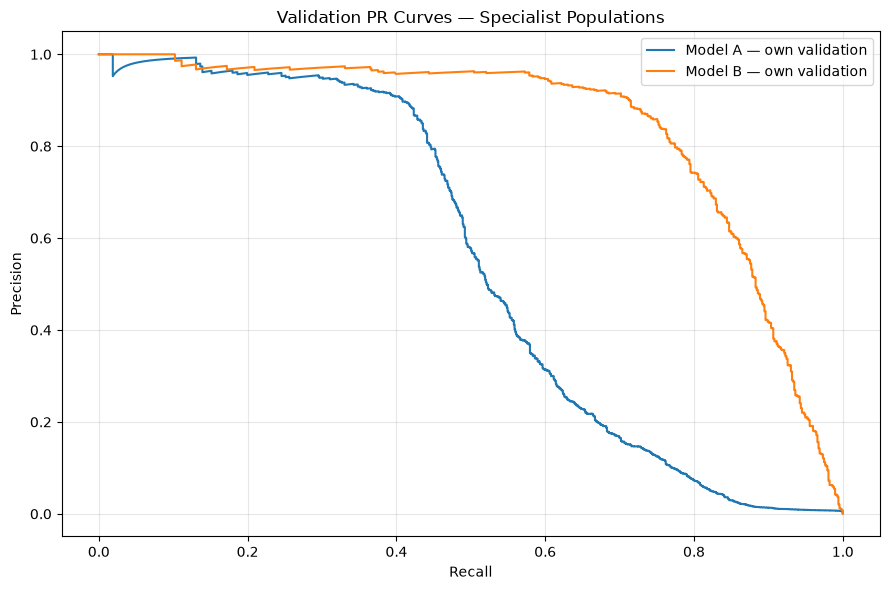

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

precision_A, recall_A, _ = precision_recall_curve(yA_val, pA_val)
precision_B, recall_B, _ = precision_recall_curve(yB_val, pB_val_spec)

plt.figure(figsize=(9, 6))
plt.plot(recall_A, precision_A, label="Model A — own validation")
plt.plot(recall_B, precision_B, label="Model B — own validation")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Validation PR Curves — Specialist Populations")
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()


In [5]:
from src.evaluation import fusion_search, select_best_fusion

fusion_table = fusion_search(pA_val, pB_val, y_complete_val)
best_fusion  = select_best_fusion(fusion_table)
print(best_fusion)


family           weighted
rule             weighted
w_pattern             0.2
w_unpatterned         0.8
floor                0.15
threshold        0.071857
precision        0.150429
recall           0.726246
f1               0.249233
Name: 26, dtype: object


In [ ]:
from src.evaluation import eval_binary
import numpy as np

pA_test = model_A.predict_proba(X_complete_test)[:, 1]
pB_test = model_B.predict_proba(X_complete_test)[:, 1]

pred_A = (pA_test >= OP_THRESHOLD_A).astype(np.int8)
pred_B = (pB_test >= OP_THRESHOLD_B).astype(np.int8)

test_comparison = pd.DataFrame([
    eval_binary(y_complete_test, pred_A, pA_test, "Model A — General AML"),
    eval_binary(y_complete_test, pred_B, pB_test, "Model B — Pattern Specialist"),
])
print(test_comparison.round(6))


In [7]:
# ── Patterned / unpatterned breakdown ─────────────────────────────────────────
test_meta = df.iloc[test_idx][["row_id","target","txt_pattern_memberships","txt_patterned"]].copy()
test_meta["pA"] = pA_test; test_meta["pB"] = pB_test
test_meta["pred_A"] = pred_A; test_meta["pred_B"] = pred_B
test_meta["group"] = np.where(
    test_meta["target"].eq(1) & test_meta["txt_patterned"].eq(1), "Patterned laundering",
    np.where(test_meta["target"].eq(1) & test_meta["txt_patterned"].eq(0), "Unpatterned laundering", "Normal"))

group_rows = []
for group_name, g in test_meta.groupby("group", sort=False):
    y_g = g["target"].to_numpy()
    def grp_recall(pred_col):
        pos = y_g.astype(bool)
        return float(g.loc[pos, pred_col].mean()) if pos.sum() > 0 else np.nan
    group_rows.append({"group": group_name, "rows": len(g), "laundering": int(y_g.sum()),
                       "Model A recall": grp_recall("pred_A"), "Model B recall": grp_recall("pred_B"),
                       "Model A alerts": int(g["pred_A"].sum()), "Model B alerts": int(g["pred_B"].sum())})
group_result = pd.DataFrame(group_rows)
print(group_result.round(4))

state.save("04_eval", (test_comparison, group_result, test_meta,
                        floor_table, OP_THRESHOLD_A, OP_THRESHOLD_B,
                        OP_PRECISION_A, OP_RECALL_A, OP_PRECISION_B, OP_RECALL_B,
                        pA_test, pB_test, pred_A, pred_B, fusion_table, best_fusion))
print("Checkpoint 04 saved.")


                    group     rows  laundering  Model A recall  \
0                  Normal  1014569           0             NaN   
1  Unpatterned laundering      459         459          0.4444   
2    Patterned laundering      806         806          0.9404   

   Model B recall  Model A alerts  Model B alerts  
0             NaN            7776            9685  
1          0.2309             204             106  
2          0.9566             758             771  
Saved checkpoint: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/04_eval.pkl
Checkpoint 04 saved.
